## Langchain Introduction



In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["DEEPSEEK_API_KEY"] = os.getenv("DEEPSEEK_API_KEY")

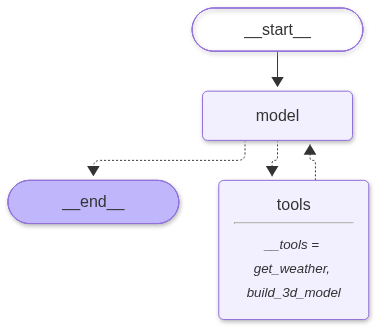

In [14]:
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

def get_weather(city: str) -> str:
    """
    Get the weather for a given city.
    """
    return f"The weather in {city} is sunny."

def build_3d_model(object_name: str) -> str:
    """
    Build a 3D model for a given object.
    """
    return f"Building a 3D model of {object_name}."

model = ChatOpenAI(
    model="deepseek-chat",
    api_key=os.environ["DEEPSEEK_API_KEY"],
    base_url="https://api.deepseek.com",
)

agent = create_agent(
    model = model,
    tools = [get_weather, build_3d_model],
    system_prompt = "You are a helpful assistant.",
    # provider = "deepseek",
    # model: deepseek-flash
    # name: DeepSeek V4.1 Flash
)

agent

In [21]:
agent.invoke({
    "messages" : [
        {
            "role": "user",
            "content": "What is the weather in New York?"
        }
    ]
})

{'messages': [HumanMessage(content='What is the weather in New York?', additional_kwargs={}, response_metadata={}, id='765fd3e5-1e38-4eb7-bc32-57211e1487ed'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 335, 'total_tokens': 374, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 128, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 128, 'prompt_cache_miss_tokens': 207}, 'model_provider': 'openai', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': 'f9c37b55-1a4c-4780-a5bf-d757aafd759a', 'finish_reason': 'tool_calls', 'logprobs': None, 'normalized_finish_reason': 'tool_call'}, id='lc_run--01a1fdd6-dbec-7421-8293-b3dcc5e87856-0', tool_calls=[{'name': 'get_weather', 'args': {'city': 'New York'}, 'id': 'call_00_byNTa0BeunMDUP7ztWzu3429', 'type': 'tool_call

#### direct way of getting output

In [24]:
response = agent.invoke({
    "messages" : [
        {
            "role": "user",
            "content": "What is the weather in New York?"
        }
    ]
})

response["messages"][-1].content

'The weather in New York is sunny. ☀️'

In [25]:
agent.invoke({
    "messages" : [
        {
            "role": "user",
            "content": "What is the meanikng of love? and How should men approach to women in islam?"
        }
    ]
})

{'messages': [HumanMessage(content='What is the meanikng of love? and How should men approach to women in islam?', additional_kwargs={}, response_metadata={}, id='c1743e36-f3af-44cb-9b53-d995046aa1ea'),
  AIMessage(content='These are two very different questions—one philosophical/spiritual and one practical/religious—so let me address them separately.\n\n## On the meaning of love\n\nLove is notoriously hard to define, but it\'s often understood on several levels:\n\n- **As an emotion** — deep affection, attachment, and care for someone or something.\n- **As a choice/action** — a commitment to act in another\'s interest, to be patient, forgiving, and loyal (many traditions treat love as something you *do*, not just *feel*).\n- **As a spiritual concept** — in religious frameworks, love is often the connective principle of existence. In Islam specifically, love (*maḥabba*) is central: love of God, love of the Prophet, love of family and neighbor, and divine mercy (*raḥma*) as a cosmic pri